In [1]:
from __future__ import annotations

from sklearn.datasets import make_moons
import torch

from examples.utils.model import MLPClassifier
from examples.utils.plotting import plot_example_uncertainty
from probly.representer import representer
from probly.transformation import ensemble

In [2]:
X, y = make_moons(n_samples=500, noise=0.05, random_state=0)
X_tensor = torch.from_numpy(X).float()
y_tensor = torch.from_numpy(y).long()

In [3]:
base_model = MLPClassifier()

ensemble_model = ensemble(
    base_model,
    num_members=3,
    reset_params=True,  # fresh init per member maximizes diversity
    predictor_type="logit_classifier",
)

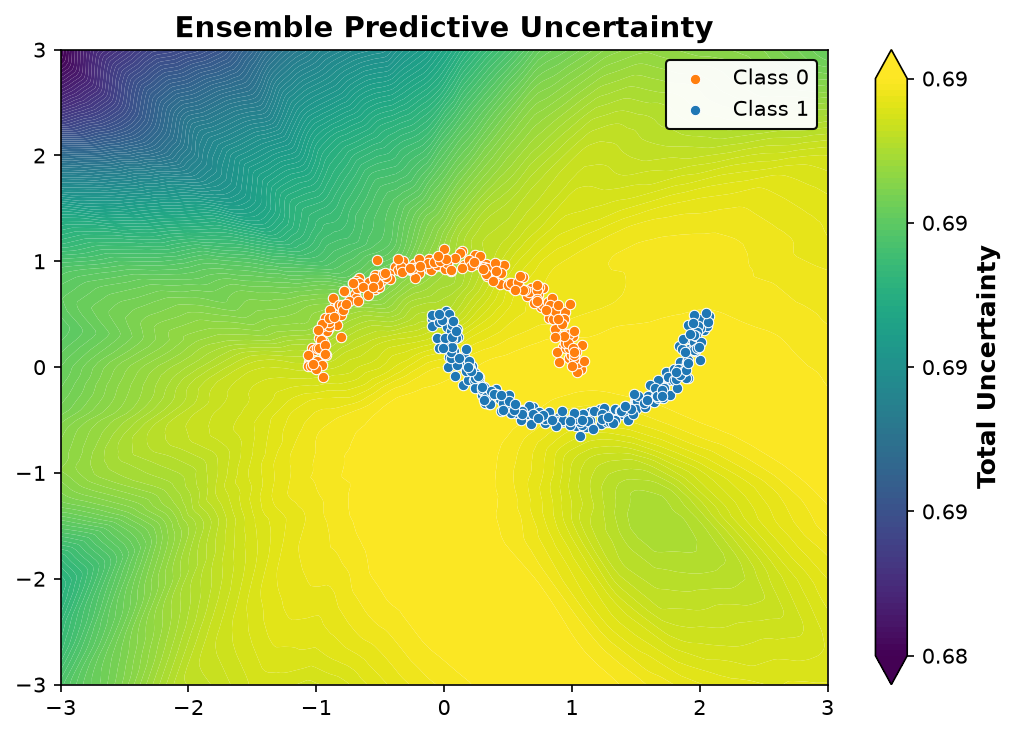

In [4]:
ensemble_model.eval()
rep = representer(ensemble_model)

plot = plot_example_uncertainty(X, y, rep, title="Ensemble Predictive Uncertainty", notion="total")
plot.show()